# Die Verwendung von Bibliotheken

::: {.callout-note}
### Lernziele {.unnumbered}
Nach diesem Kapitel können Sie …

- Module importieren, Aliase verwenden, fehlende Pakete installieren und die Begriffe Modul, Paket und Bibliothek unterscheiden
- NumPy-Arrays erzeugen und für Matrixoperationen, Vektorisierung und Broadcasting nutzen
- Funktionen und Messwerte mit Matplotlib darstellen (Linien-, Streu- und Balkendiagramm) und eine Ausgleichskurve anpassen
- Messdaten mit pandas einlesen, sich einen Überblick verschaffen und neue Größen berechnen
:::

In diesem Kapitel führen wir kurz in die Verwendung von Bibliotheken ein. Es gibt unzählige praktische Bibliotheken, die Entwicklerinnen und Entwicklern auf der ganzen Welt das Leben leichter machen. Natürlich können wir im Rahmen dieser Einführung nur einen kurzen Einblick geben: Wir erklären allgemein, was eine Bibliothek ist, wie man sie verwendet und installiert, und werfen dann einen exemplarischen Blick auf bekannte Bibliotheken, die Ihnen mit hoher Wahrscheinlichkeit in Ihren Projekten begegnen und helfen werden. 

## Einführung

Eine **Bibliothek** ist eine Sammlung von fertigem Code, die Sie in Ihrem Programm nutzen können. So müssen Sie das Rad nicht immer wieder neu erfinden! Außerdem sind Bibliotheken oft hochoptimiert, teilweise "unter der Haube" in anderen Programmiersprachen geschrieben, um eine bessere Performance zu erzielen (z.B. in C oder C++).

Bevor wir eine Bibliothek in unserem Programm verwenden können, müssen wir sie **importieren**: 

In [168]:
import math  # importiert die Bibliothek math 

# jetzt kann math genutzt werden und das geht so:

print(math.sqrt(256))  # Wurzel ziehen
print(math.cos(2*math.pi))  # Trigonometrie
print(math.factorial(5))  # Fakultät

# vieles mehr ist möglich mit math ...

16.0
1.0
120


Wie Sie am Beispiel erkannt haben, wird der Name der Bibliothek den Funktionen vorangestellt. Über den `.` greifen Sie auf die Inhalte der Bibliothek zu. Man kann auch nur ausgewählte Elemente der Bibliothek importieren:

In [169]:
from math import cos, sin, pi  # nur die genannten werden importiert

print(cos(2*pi) + sin(2*pi))  # das Präfix math fällt weg

0.9999999999999998


**Tipp:** Ich bevorzuge es, zu sehen, aus welcher Bibliothek die Funktionen stammen. So werden auch potenzielle Konflikte mit eigenen Bezeichnungen vermieden. Daher nutze ich meistens die obere Variante.

### Aliase {.unnumbered}

Es ist möglich und auch üblich, einer Bibliothek beim Importieren einen Kurznamen (sog. *Alias*) zu geben. Wir könnten z.B. die `math`-Bibliothek mit `m` abkürzen:

In [171]:
import math as m  # importiert math mit Alias m

# Verwendung:
print(m.sqrt(225), m.cos(m.pi), m.factorial(3))

15.0 -1.0 6


Häufig verwendete Bibliotheken haben mittlerweile Standard-Aliase, die so gut wie immer verwendet werden. Wir listen einige berühmte Beispiele auf:

|Bibliothek|Typischer Alias|Import|Anwendungsbereich|
|---|---|---|---|
|numpy	| np	| import numpy as np| Numerische Mathematik|
|matplotlib.pyplot |	plt	| import matplotlib.pyplot as plt| Visualisierung / Diagramme |
|pandas	| pd	| import pandas as pd| 	Datenanalyse und Tabellenverarbeitung |
|seaborn	| sns	| import seaborn as sns| Statistische Datenvisualisierung |
|tensorflow |	tf	| import tensorflow as tf| Maschinelles Lernen / Neuronale Netze |

### Installation {.unnumbered}

Nicht alle Bibliotheken sind auf unserem System vorinstalliert; manche müssen bei Bedarf erst heruntergeladen und installiert werden. Das geht zum Glück mithilfe von Paketverwaltungssoftware wie *pip* oder *conda* sehr einfach. Nehmen wir an, wir möchten die Bibliothek `requests` (für HTTP-Requests) installieren:

* **Mit pip (für Standard-Python ohne Anaconda)**

    Im Terminal oder in der Konsole eingeben:

    `pip install requests`

* **Mit Anaconda**

    Starten Sie **Anaconda Prompt** und tippen Sie ein:

    `conda install requests`


* **Über die grafische Oberfläche von Anaconda**

    1. Starten Sie **Anaconda Navigator**.
    2. Wählen Sie „Environments“ und setzen Sie den Filter auf „not installed“ oder „all“.
    3. Verwenden Sie „Search Packages“, um das gewünschte Paket zu finden (z.B. requests).
    4. Häkchen setzen und „Apply“ klicken.

### Kurze Begriffsklärung: Modul, Paket, Bibliothek {.unnumbered}

Diese drei Begriffe gehen manchmal durcheinander und werden nicht immer sauber voneinander getrennt:

* **Modul:**	
    Eine einzelne Datei mit Python-Code (.py), die Funktionen, Klassen oder Variablen enthält.
* **Paket:**
    Ein strukturierter Ordner mit mehreren Modulen.
* **Bibliothek:**
    Ein allgemeiner Begriff für Module und Pakete, die bestimmte Aufgaben lösen (z.B. Datenanalyse).

Bei der praktischen Verwendung von Bibliotheken ist die Unterscheidung in der Regel nicht so wichtig: Wir importieren `math` (ein Modul) oder `pandas` (ein Paket), um Probleme zu lösen, die uns in unseren Projekten begegnen. Wenn wir dagegen selbst Module oder Bibliotheken für die Community entwickeln möchten, werden die Details natürlich wichtig. 

## NumPy
### Überblick {.unnumbered}

**NumPy (Numerical Python)** ist eine der zentralen Bibliotheken im wissenschaftlichen Rechnen mit Python. Sie bietet leistungsfähige Datenstrukturen, insbesondere das n-dimensionale Array, und eine breite Palette mathematischer Funktionen zur effizienten Verarbeitung großer Datenmengen. Für Ingenieurinnen und Ingenieure ist NumPy besonders wertvoll, da es numerische Simulationen, Datenanalyse und Algorithmenentwicklung deutlich vereinfacht und beschleunigt. Damit es keine Missverständnisse gibt: Numerisch bedeutet, dass wir in NumPy immer mit konkreten Zahlen rechnen und solche als Ergebnisse erhalten. Das Gegenteil wären symbolische Berechnungen, bei denen es darum geht, eine Formel als Lösung für ein Problem zu finden. Hierfür gibt es übrigens auch eine Python-Bibliothek: *SymPy (Symbolic Python)*. 

Drei Highlights von NumPy für die Ingenieurpraxis:

* Effiziente Matrixoperationen: Lineare Algebra ist das Rückgrat vieler ingenieurtechnischer Berechnungen, z.B. in der Statik, Regelungstechnik oder Signalverarbeitung. NumPy ermöglicht schnelle und speichereffiziente Operationen auf Matrizen – inklusive Inversion, Eigenwertberechnung oder Lösung linearer Gleichungssysteme.

* Schnelle Datenverarbeitung: Dank einer optimierten Implementierung (der rechenintensive Kern ist in C geschrieben) ist NumPy um ein Vielfaches schneller als Standard-Python-Schleifen. Das ist ideal für Messdatenanalysen oder Simulationen, bei denen Zeit eine kritische Rolle spielt.

* Nahtlose Integration mit anderen Tools: NumPy bildet die Grundlage für viele andere wissenschaftliche Bibliotheken wie SciPy, pandas oder Matplotlib. So lässt es sich leicht in bestehende Arbeitsabläufe integrieren – vom Datenimport bis zur Visualisierung der Ergebnisse.

NumPy wird üblicherweise mit dem Alias `np` importiert:

In [5]:
import numpy as np

### Arrays {.unnumbered}

In NumPy arbeitet man mit dem optimierten Datentyp `ndarray`. Wir sagen auch vereinfacht nur "Array" oder "NumPy-Array". Das "nd" steht für "n-dimensional", denn ein NumPy-Array kann genau wie die Liste als Vektor, Matrix oder höherdimensionaler Tensor (Verallgemeinerung einer Matrix auf mehr Dimensionen) angelegt werden. Es gibt einen wichtigen Unterschied zur Liste: **Alle Elemente eines NumPy-Arrays müssen denselben Datentyp haben!**

#### Erzeugung von Arrays {.unnumbered}

Arrays werden typischerweise aus Listen erzeugt oder mit speziellen Funktionen:

In [26]:
# 1-dimensionales Array aus einer Python-Liste
vector = np.array([1, 2, 3, 4])
print(vector)

[1 2 3 4]


In [27]:
print(type(vector))

<class 'numpy.ndarray'>


In [28]:
# 2-dimensionales Array aus einer Python-Liste
matrix = np.array([[1, 2],[3, 4]])
print(matrix)  # erkennen Sie den Unterschied zu der Ausgabe einer verschachtelten Liste?

[[1 2]
 [3 4]]


In [29]:
print(type(matrix))

<class 'numpy.ndarray'>


In [30]:
# Mit np.zeros und np.ones
zeros = np.zeros((2, 3))  # 2 x 3 Matrix mit Nullen 
print(zeros)

[[0. 0. 0.]
 [0. 0. 0.]]


In [31]:
ones = np.ones((3, 4))  # 3 x 4 Matrix mit Einsen
print(ones)

[[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]


In [32]:
# Mit np.arange(start, stop, step)
# verhält sich analog zu range(start, stop, step), aber step kann auch ein Float sein!
arange_test = np.arange(0, 10, 2) 
print(arange_test)

[0 2 4 6 8]


In [33]:
arange_test2 = np.arange(0, 5, 0.5)  # step ist hier ein Float
# Vorsicht: Bei Float-Schrittweiten können Rundungsfehler ein Element zu viel oder zu wenig
# erzeugen – für eine feste Anzahl Punkte besser np.linspace verwenden (siehe unten).
print(arange_test2)

[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5]


In [34]:
# Mit np.linspace(start, stop, num) 
# erzeugt man ein Array mit äquidistanten Punkten zwischen
# den Grenzen start und stop (standardmäßig beide eingeschlossen!). 
# Es werden insgesamt num Punkte erzeugt.

linspace_test = np.linspace(0, 1, 5)

# Es werden exakt 5 äquidistante Werte von 0 bis 1 erzeugt
print(linspace_test)

[0.   0.25 0.5  0.75 1.  ]


In [35]:
# Ein zweites Beispiel:
linspace_test2 = np.linspace(-2, 3, 10)

# Es werden exakt 10 äquidistante Werte von -2 bis 3 erzeugt
print(linspace_test2)

[-2.         -1.44444444 -0.88888889 -0.33333333  0.22222222  0.77777778
  1.33333333  1.88888889  2.44444444  3.        ]


::: {.callout-caution}
#### Der Parameter `endpoint` von `np.linspace` {.unnumbered}
Bei `np.linspace(start, stop, num)` sind Anfangs- **und** Endwert standardmäßig inkludiert! Dies ist ein wichtiger Unterschied zu `np.arange(start, stop, step)` oder `range(start, stop, step)`.

Möchte man den Endwert bei `np.linspace` bewusst exkludieren, kann dies über das Keyword-Argument `endpoint` erfolgen:
`np.linspace(start, stop, num, endpoint = False) # Endpunkt ausgeschlossen`
:::

#### Dimensionen und Shape {.unnumbered}

Jedes Array hat die Attribute `.ndim` (Anzahl Dimensionen), `.shape` (Größe pro Dimension) und `.size` (Gesamtzahl der Elemente):

In [39]:
my_array = np.array([[1, 2, 3], [4, 5, 6]])
print("Array:")
print(my_array)
print("Dimensionen:", my_array.ndim)  # Matrix, also 2-dimensional
print("Shape:", my_array.shape)  # 2 x 3 Matrix
print("Anzahl Elemente:", my_array.size)  # 6 Elemente 

Array:
[[1 2 3]
 [4 5 6]]
Dimensionen: 2
Shape: (2, 3)
Anzahl Elemente: 6


In [41]:
my_array = np.array([1, 2, 3, 4])
print("Array:")
print(my_array)
print("Dimensionen:", my_array.ndim)  # Vektor, also 1-dimensional
print("Shape:", my_array.shape)  # Vektor mit Länge 4
print("Anzahl Elemente:", my_array.size)  # 4 Elemente

Array:
[1 2 3 4]
Dimensionen: 1
Shape: (4,)
Anzahl Elemente: 4


**Beachten Sie, dass `shape` immer vom Typ `tuple` ist!**

#### Indexzugriff und Slicing {.unnumbered}

Der Zugriff auf Elemente erfolgt ähnlich wie bei Python-Listen.
Bei mehrdimensionalen Arrays werden die Indizes jedoch **durch Kommata getrennt** innerhalb eines einzigen Paares von eckigen Klammern.

In [43]:
my_array = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]])
print("Array:")
print(my_array)

# Einzelne Elemente
print("my_array[0, 0] =", my_array[0, 0])
print("my_array[2, 1] =", my_array[2, 1])

Array:
[[10 20 30]
 [40 50 60]
 [70 80 90]]
my_array[0, 0] = 10
my_array[2, 1] = 80


In [49]:
# Slicing (Logik wie bei Python-Listen)
print("Komplette Matrix:\n", my_array)
print("Erste Zeile:", my_array[0, :])
print("Zweite Spalte:", my_array[:, 1])
print("Teilarray:\n", my_array[1:, :])

Komplette Matrix:
 [[10 20 30]
 [40 50 60]
 [70 80 90]]
Erste Zeile: [10 20 30]
Zweite Spalte: [20 50 80]
Teilarray:
 [[40 50 60]
 [70 80 90]]


Ein wichtiger Unterschied zu Python-Listen betrifft das Slicing. Bei einer Liste erzeugt ein Slice wie `liste[0:2]` eine (flache) **Kopie** der Liste (siehe Kapitel *Datenstrukturen*). Bei einem NumPy-Array entsteht dagegen **keine Kopie**, sondern eine sog. **View** (Ansicht): ein neues Array-Objekt, das auf dieselben Daten im Speicher zeigt. NumPy spart sich so das Kopieren, was bei großen Arrays viel Zeit und Speicher spart. Die Kehrseite: Ändert man die View, ändert sich auch das ursprüngliche Array – ein Seiteneffekt, wie wir ihn von Listen kennen, wenn zwei Variablen auf dieselbe Liste zeigen:

In [ ]:
data = np.array([[1, 2, 3],
                 [4, 5, 6]])

row = data[0, :]   # View auf die erste Zeile (keine Kopie!)
row[0] = 99        # wir ändern die View ...
print(data)        # ... und das Original hat sich mitgeändert!

[[99  2  3]
 [ 4  5  6]]


Zum Vergleich dasselbe Vorgehen mit einer Liste. Hier ist der Slice eine Kopie, das Original bleibt unverändert:

In [ ]:
numbers = [1, 2, 3]
part = numbers[0:2]  # Kopie der ersten beiden Elemente
part[0] = 99
print(numbers)       # unverändert

[1, 2, 3]


Wenn Sie mit einem Ausschnitt eines Arrays weiterarbeiten wollen, ohne das Original zu verändern, erzeugen Sie mit `.copy()` ausdrücklich eine Kopie:

In [ ]:
row_copy = data[1, :].copy()  # echte Kopie der zweiten Zeile
row_copy[0] = -1
print(row_copy)
print(data)                   # unverändert

[-1  5  6]
[[99  2  3]
 [ 4  5  6]]


### Demo: Matrixoperationen mit Arrays {.unnumbered}

In [78]:
import numpy as np
# 3x3 Matrix als np.array
A = np.array([[2, 1, 3],
              [0, -1, 4],
              [5, 2, 0]])

# ein Vektor
b = np.array([1, 2, 3])

# Matrix mal Vektor (Matrix-Vektor-Produkt):
v = np.dot(A, b)

# WARNUNG: Es ist wichtig, np.dot zu verwenden und nicht *
# Letzteres führt kein Matrix-Vektor-Produkt, sondern eine 
# elementweise Multiplikation durch! 

print("np.dot(A, b) =", v)

np.dot(A, b) = [13 10  9]


Es gibt auch eine Kurzschreibweise für `np.dot(..)` mit dem `@`-Operator:

In [79]:
print("A @ b =", A @ b)

A @ b = [13 10  9]


Wir demonstrieren einmal, was passiert, wenn man mit dem `*`-Operator multipliziert:  

In [82]:
print(A * b) # elementweise Multiplikation! Das ist NICHT das Matrixprodukt!

[[ 2  2  9]
 [ 0 -2 12]
 [ 5  4  0]]


::: {.callout-caution}
#### Skalar- und Matrixprodukte immer mit `np.dot(...)` oder dem `@`-Operator! {.unnumbered}
:::

Auch das **Kreuzprodukt** ist in NumPy verfügbar: 

In [56]:
v = np.array([1, 2, 3])
w = np.array([0, -1, 1])
z = np.cross(v, w)
print(z)

[ 5 -1 -1]


Wir können viele Operationen aus der linearen Algebra direkt ausführen:

In [3]:
A.T  # liefert die transponierte Matrix
# alternativ: np.transpose(A)

array([[ 2,  0,  5],
       [ 1, -1,  2],
       [ 3,  4,  0]])

In [4]:
np.linalg.eigvals(A)  # liefert die Eigenwerte von A

array([ 5.83891641, -0.80708431, -4.0318321 ])

In [5]:
np.linalg.eig(A)  # liefert Eigenwerte und Eigenvektoren von A

EigResult(eigenvalues=array([ 5.83891641, -0.80708431, -4.0318321 ]), eigenvectors=array([[-0.62757479, -0.37722073, -0.16597401],
       [-0.39307122,  0.92504816, -0.78589196],
       [-0.67204531,  0.04461408,  0.59567311]]))

#### Lineare Gleichungssysteme mit NumPy lösen {.unnumbered}

Gesucht ist die Lösung eines linearen Gleichungssystems: 

$$
\begin{aligned}
2\,x_1 + x_2 + 3\,x_3 &= 1 \\
-x_2 + 4\,x_3 &= 2 \\
5\,x_1 + 2\,x_2 &= 3
\end{aligned}
$$

In Matrixschreibweise: 
$$
\begin{pmatrix}
2 & 1 & 3 \\
0 & -1 & 4 \\
5 & 2 & 0
\end{pmatrix}
\begin{pmatrix}
x_1 \\[4pt]
x_2 \\[4pt]
x_3
\end{pmatrix}
=
\begin{pmatrix}
1 \\[4pt]
2 \\[4pt]
3
\end{pmatrix}
$$

In NumPy legen wir die Koeffizientenmatrix und den Vektor auf der rechten Seite als Arrays an:

In [65]:
A = np.array([[2., 1., 3.],
              [0., -1., 4.],
              [5., 2., 0.]])

b = np.array([1., 2., 3.])

Der Aufruf `np.linalg.solve(A, b)` löst das lineare Gleichungssystem:

In [66]:
x = np.linalg.solve(A, b)  # finde x, so dass A x = b
print(x)

[ 1.31578947 -1.78947368  0.05263158]


Überprüfen wir das Ergebnis, indem wir `A x` berechnen und mit `b` vergleichen:

In [67]:
print(A @ x, "Zum Vergleich: ", b)

[1. 2. 3.] Zum Vergleich:  [1. 2. 3.]


<div class="exercises">
    
<b>Übung:</b> 
Lineare Gleichungssysteme begegnen uns bei der Lösung verschiedener technischer Probleme, z.B. bei statischen Berechnungen oder der Bestimmung von Strömen und Spannungen in Schaltkreisen. Als Beispiel sei das folgende System für drei unbekannte Ströme gegeben, das mithilfe der kirchhoffschen Regeln für Gleichstromnetze hergeleitet wurde [[Komplette Aufgabe "Stromkreis mit drei Maschen"]( https://www.leifiphysik.de/elektrizitaetslehre/komplexere-schaltkreise/grundwissen/kirchhoffsche-gesetze-fuer-fortgeschrittene)]: 
$$
\begin{aligned}
I_1 - I_2 - I_3 &= 0 \\
-10.8 \,V + I_1\cdot 6\,\Omega + I_2\cdot 8\,\Omega &= 0 \\
3.2\,V + I_3 \cdot 4\,\Omega - I_2\cdot 8\,\Omega &= 0
\end{aligned}
$$

Bestimmen Sie die drei unbekannten Ströme $I_1, I_2, I_3$ mithilfe von NumPy!
</div>

In [73]:
#| code-fold: true
#| output: false
import numpy as np
# Die Lösung erfolgt in 3 Schritten:

# 1. Zunächst bringen wir das Gleichungssystem in die richtige Form! 
# Da nur SI-Einheiten verwendet werden, können wir alle Einheiten weglassen und wissen, dass das Ergebnis in Ampere sein wird.
#1 I_1 - 1 I_2 - 1 I_3 = 0 
#6 I_1 + 8 I_2 + 0 I_3 = 10.8 
#0 I_1 - 8 I_2 + 4 I_3 = -3.2

# 2. Jetzt legen wir Matrix und rechte Seite als Arrays an: 
A = np.array([[1., -1., -1.], [6., 8., 0.], [0., -8., 4]])
b = np.array([0., 10.8, -3.2])

# 3. Jetzt lösen wir das System:
I = np.linalg.solve(A, b)

print("Die drei unbekannten Stromstärken sind:")
print(f"I_1 = {I[0]: .2f} A")
print(f"I_2 = {I[1]: .2f} A")
print(f"I_3 = {I[2]: .2f} A")

Die drei unbekannten Stromstärken sind:
I_1 =  1.00 A
I_2 =  0.60 A
I_3 =  0.40 A


### Demo: Vektorisierung {.unnumbered}

NumPy bietet vektorisierten Code, d. h. mathematische Operationen wie Addition, Subtraktion, Multiplikation auf Arrays werden auf alle Elemente angewendet, ohne dass wir eine Schleife schreiben müssen (die Schleife läuft intern in schnellem, kompiliertem Code). Dies ist viel schneller als manuelle Schleifen über Listen!

Wir erstellen zunächst ein Array mit $x$-Werten, an denen wir eine Funktion auswerten wollen: 

In [20]:
x_values = np.array(range(10))  # Array mit den x-Werten 0, 1, 2, ..., 9  
print(x_values)

[0 1 2 3 4 5 6 7 8 9]


An diesen Stellen sollen Funktionswerte der folgenden Funktion berechnet werden: $f(x) = 3\,x^3 - x^2 + 2\,x + 1$. Vektorisierung bedeutet, dass wir die Rechenoperationen mit dem Array `x_values` durchführen können und NumPy diese elementweise durchführt. Das ist kinderleicht:  

In [19]:
f_values = 3 * x_values**3 - x_values**2 + 2 * x_values + 1  # berechnet f(x) für jeden x-Wert
print(f_values) # das Ergebnis ist wieder ein Array!

[   1    5   25   79  185  361  625  995 1489 2125]


Wir benötigen keine Schleife und die Operationen werden sogar optimiert, also sehr schnell, ausgeführt. In der numerischen Mathematik kommen solche Operationen sehr häufig vor. Im Abschnitt zu Matplotlib werden wir sehen, wie man Vektorisierung verwendet, um mit wenigen Zeilen einen Funktionsgraphen zu zeichnen. 

Wir können natürlich auch komplexere mathematische Funktionen berechnen. Das wollen wir an $g(x) =\frac{1}{2} \sqrt{x}$ und $h(x) = x\, e^{x^2}$ demonstrieren: 

In [12]:
g_values = 1/2 * np.sqrt(x_values)  # berechnet Funktionswerte von g an den x-Stellen
print(g_values)

[0.         0.5        0.70710678 0.8660254  1.         1.11803399
 1.22474487 1.32287566 1.41421356 1.5       ]


In [15]:
h_values = x_values * np.exp(x_values**2) # berechnet Funktionswerte von h an den x-Stellen
print(h_values)

[0.00000000e+00 2.71828183e+00 1.09196300e+02 2.43092518e+04
 3.55444421e+07 3.60024497e+11 2.58673893e+16 1.33514260e+22
 4.98811926e+28 1.35548758e+36]


Wichtig ist, dass wir in den beiden letzten Beispielen die Mathe-Funktionen aus NumPy verwendet haben, also `np.sqrt(...)` bzw. `np.exp(...)`. Andere Mathebibliotheken (z.B. `math`) sind nicht für vektorisierte Operationen auf NumPy-Arrays ausgelegt.  

Die beiden Funktionen `np.linspace(...)` und `np.arange(...)` werden oft zusammen mit Vektorisierung verwendet. Zum Beispiel erstellt man mit `np.linspace(...)` ein Array von $x$-Werten und berechnet dann mithilfe von Vektorisierung die zugehörigen $y$-Werte einer Funktion. Das könnte so aussehen wie im folgenden Beispiel:    

In [74]:
xs = np.linspace(-np.pi, np.pi, 100)  # 100 Punkte zwischen -pi und pi
ys = np.sin(xs)  # Funktionswerte von sin(x) an den zuvor berechneten Stellen
print("Auswertung an einer Beispielstelle:")
print("x =", round(xs[20],2), ", sin(x)=", round(ys[20],2))

# Teaser: Matplotlib kann mit diesen Werten einen Funktionsgraphen zeichnen!

Auswertung an einer Beispielstelle:
x = -1.87 , sin(x)= -0.95


### Demo: Broadcasting {.unnumbered}

NumPy unterstützt sog. "Broadcasting", sodass auch Arrays unterschiedlicher Formen miteinander rechnen können, ohne dass wir diese mühsam aneinander anpassen müssen.

Ein Beispiel zu Broadcasting:

In [190]:
A = np.array([[1, 0, 0],
              [0, 2, 0],
              [0, 0, 3]])

v = np.array([1, 2, 3])

B = A + v  # das passt eigentlich nicht!

Die letzte Zeile führt überraschenderweise nicht zu einem Programmfehler, obwohl man A und v mathematisch gar nicht addieren kann. In solchen Fällen geschieht Broadcasting: "Was nicht passt, wird passend gemacht (*falls möglich*)!". Schauen wir uns das Ergebnis genauer an:  

In [31]:
print(B)  

[[2 2 3]
 [1 4 3]
 [1 2 6]]


Wir sehen: Der Vektor v wurde zu jeder Zeile von A addiert – so, als hätte man ihn dreimal untereinander geschrieben. Die Regel dahinter: NumPy vergleicht die Formen (*shapes*) der Arrays von hinten. Zwei Dimensionen passen zusammen, wenn sie gleich sind oder eine davon 1 ist bzw. fehlt. Entlang einer solchen Dimension mit Größe 1 (bzw. einer fehlenden) wird das Array gedanklich vervielfältigt – hier wird aus der Form (3,) die Form (3, 3). Passen die Formen nicht zusammen, meldet NumPy einen `ValueError`. Man muss aufpassen, dass man kein unbeabsichtigtes Broadcasting durchführt und unerwartete Ergebnisse erhält.

<div class="exercises">
<b>Übungen:</b>
    
1. Erzeugen Sie 100 $x$-Werte zwischen $-2$ und $5$ und berechnen Sie zu jedem dieser Werte den Funktionswert von $f(x) = \frac{e^{-x}}{1 + x^2}$. Geben Sie exemplarisch den Funktionswert für ein zufällig ausgewähltes $x$ aus (auf zwei Nachkommastellen gerundet)! 
2. Erzeugen Sie ein Array, das 1000 Zeitpunkte zwischen t=0 s und t= 100 s beinhaltet. Ein Körper befinde sich zum Zeitpunkt t=0 an der Position x(0)=0 und bewege sich gleichmäßig mit der Geschwindigkeit v= 2.5 m/s in positive x-Richtung. Erstellen Sie ein Array, das die x-Position zu jedem Zeitpunkt t angibt. Geben Sie die Position zum Zeitpunkt t=100 s aus. 
3. Multiplizieren Sie zwei 3x3 Matrizen miteinander.
4. Wie können Sie Broadcasting und Transponieren kombinieren, um einen Vektor v zu jeder Spalte einer Matrix zu addieren? 
</div>

Lösungen:

In [75]:
#| code-fold: true
#| output: false
import numpy as np
# Übung 1 
xs = np.linspace(-2, 5, 100)
ys = np.exp(-xs)/(1 + xs**2)
print(f"Übung 1: f({round(xs[30],2)}) = {round(ys[30],2)}")

# Übung 2
ts = np.linspace(0,100, 1000)
xs = 2.5 * ts  # x = velocity * time
print("\nÜbung 2:\nx(t = 100s) =", xs[-1])

# Übung 3
A = np.array([[1, 2, 3],
     [1, 2, 3],
     [1, 2, 3]])

B = np.ones((3, 3))

C = np.dot(A, B)  # oder C = A @ B

print("\nÜbung 3:", "A =", A, "B = ",B, "A @ B = ", C, sep="\n")

# Übung 4
A = np.array([[1, 2, 3],
              [1, 2, 3],
              [1, 2, 3]])
v = np.array([-1, 0, -2])  # soll zu jeder Spalte addiert werden

# A wird transponiert und v addiert,
# dann wird das Ergebnis zurücktransponiert:

result = (A.T + v).T

print("\nÜbung 4:","A =", A,"v =",v, "A + v (spaltenweise)", result, sep="\n")


Übung 1: f(0.12) = 0.87

Übung 2:
x(t = 100s) = 250.0

Übung 3:
A =
[[1 2 3]
 [1 2 3]
 [1 2 3]]
B = 
[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
A @ B = 
[[6. 6. 6.]
 [6. 6. 6.]
 [6. 6. 6.]]

Übung 4:
A =
[[1 2 3]
 [1 2 3]
 [1 2 3]]
v =
[-1  0 -2]
A + v (spaltenweise)
[[ 0  1  2]
 [ 1  2  3]
 [-1  0  1]]


## Matplotlib

**Matplotlib** ist die Standard-Bibliothek in Python zum Erstellen von Diagrammen. Der am häufigsten verwendete Teil ist das Untermodul **pyplot** (eine Schnittstelle, über die das Modul leicht zu bedienen ist), das man fast immer mit dem Alias `plt` importiert.

In [14]:
import matplotlib.pyplot as plt  # Standard-Import für matplotlib

Mit Matplotlib kann man die unterschiedlichsten Arten von Diagrammen erzeugen. Auch hier können wir nur ein paar exemplarische Beispiele demonstrieren.

### Eine Funktion plotten {.unnumbered}

Um eine Funktion zu plotten, arbeiten wir mit Matplotlib und NumPy zusammen: NumPy erzeugt die x- und y-Werte, Matplotlib stellt diese in einem einfachen Linienplot dar. Linienplot heißt, dass gerade Linien von Punkt zu Punkt gezogen werden. Wenn es ausreichend viele Punkte sind, entsteht der Eindruck einer glatten Kurve. Los geht's:

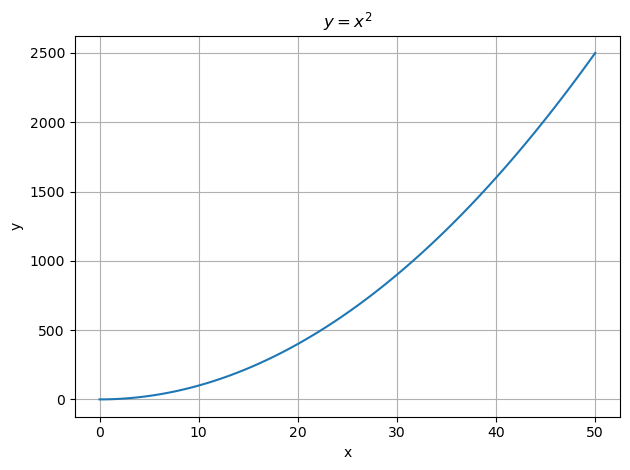

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Punkte erzeugen mit NumPy

x_values = np.linspace(0, 50, 100) # 100 Punkte zwischen 0 und 50
y_values = x_values**2 # Vektorisierung: so einfach rechnet man mit NumPy-Arrays!

# Liniendiagramm erzeugen mit Matplotlib 

plt.plot(x_values, y_values)

# Es folgen Einstellungen zur Darstellung (z.B. Beschriftung)

plt.title(r"$y = x^2$")  # Titel 
plt.xlabel("x")  # Beschriftung x-Achse
plt.ylabel("y")  # Beschriftung y-Achse
plt.tight_layout() # optimiert bei Bedarf den Zeichenbereich, damit nichts abgeschnitten wird
plt.grid(True) # zeigt ein Gitter zum einfacheren Ablesen der Werte

# Finally:
# Der eigentliche Befehl zum Rendern (= Zeichnen).

plt.show()  # öffnet ein Fenster (oder rendert im Notebook) und zeigt den Plot.

# PS: Der Befehl plt.show() wird von Jupyter oft automatisch aufgerufen, an anderer Stelle braucht man
# ihn aber explizit. Wir schreiben ihn daher immer hin.  

:::{.callout-tip}
#### Verwendung von LaTeX-Befehlen in Strings {.unnumbered}
Beim Plotten von Funktionen verwendet man häufig LaTeX-Befehle, um Achsen, Titel oder Labels zu beschriften. Beispielsweise kann die Funktion

$f(x)=\frac{1}{1+x^2}$

in Matplotlib so als String dargestellt werden:

`"$\frac{1}{1+x^2}$"`


In Python hat der Backslash `\` jedoch die Bedeutung eines *Escape-Zeichens*, z.B. für Zeilenumbrüche (`\n`) oder Tabulatoren (`\t`).
Damit Python den Backslash in LaTeX-Befehlen **wörtlich** interpretiert, verwendet man **Raw Strings**, indem man ein kleines **r** vor das String-Literal setzt:

`r"$\frac{1}{1+x^2}$"`

`r"$\sqrt{x}$"`


Dieses r teilt dem Python-Interpreter mit, dass alle Backslashes in diesem String unverändert bleiben, wodurch LaTeX-Befehle korrekt dargestellt werden.
:::

### Messwerte in einem Streudiagramm darstellen {.unnumbered}

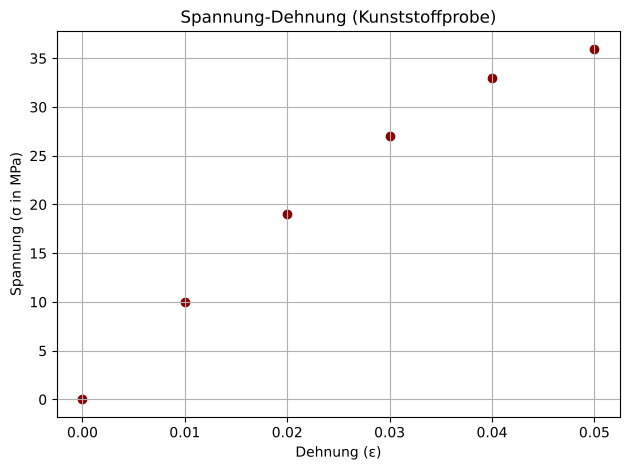

In [ ]:
import matplotlib.pyplot as plt

# Messwerte
dehnung = [0.0, 0.01, 0.02, 0.03, 0.04, 0.05]
spannung = [0, 10, 19, 27, 33, 36]  # in MPa

# Streudiagramm mit Matplotlib erzeugen
plt.scatter(dehnung, spannung, color='darkred')

# Einstellungen für die Darstellung:
plt.title("Spannung-Dehnung (Kunststoffprobe)")
plt.xlabel("Dehnung (ε)")
plt.ylabel("Spannung (σ in MPa)")
plt.grid(True)
plt.tight_layout()

# Finally: Rendern
plt.show()


Haben Sie auch sofort den Gedanken: *"Kann ich da eine Kurve durchlegen?"*

Sie können! Allerdings muss die Kurve zunächst berechnet werden, Matplotlib ist nur für die visuelle Darstellung verantwortlich. Eine einfache Möglichkeit bietet NumPy mit polynomialer Regression: Ein Polynom vorgegebenen Grades wird an die Messwerte angepasst. Das sieht im Ergebnis zum Beispiel so aus: 

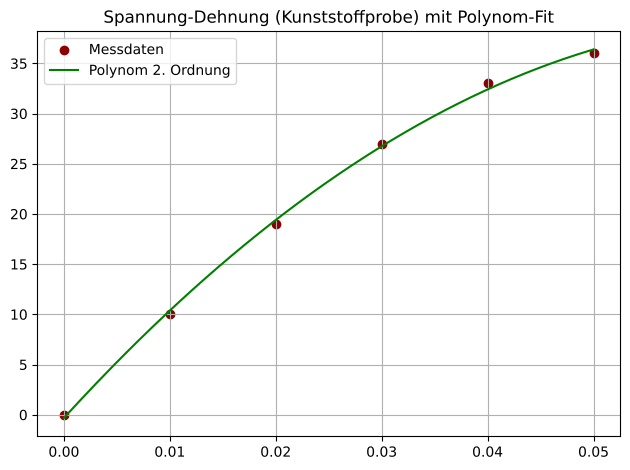

In [ ]:
#| code-fold: true
# Polynom 2. Ordnung fitten
from numpy.polynomial import Polynomial
polynom = Polynomial.fit(dehnung, spannung, deg=2)
x_poly = np.linspace(min(dehnung), max(dehnung), 200) # x-Werte für das Polynom

# Plotten
plt.scatter(dehnung, spannung, label="Messdaten", color='darkred')
plt.plot(x_poly, polynom(x_poly), label="Polynom 2. Ordnung", color="green")

# Einstellungen zur Darstellung
plt.title("Spannung-Dehnung (Kunststoffprobe) mit Polynom-Fit")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Finally: Rendern
plt.show()

### Ein einfaches Balkendiagramm {.unnumbered}

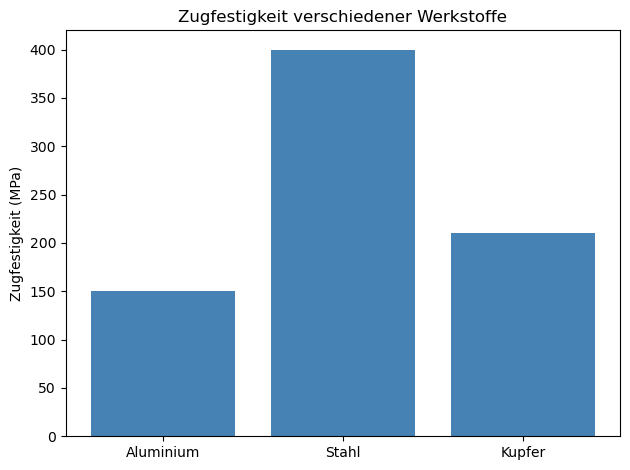

In [196]:
# Daten
werkstoffe = ["Aluminium", "Stahl", "Kupfer"]
festigkeit = [150, 400, 210]  # in MPa

# Plotten
plt.bar(werkstoffe, festigkeit, color='steelblue')

# Einstellungen zur Darstellung
plt.title("Zugfestigkeit verschiedener Werkstoffe")
plt.ylabel("Zugfestigkeit (MPa)")
plt.tight_layout()

# Finally: Rendern
plt.show()

<div class="exercises">
<b>Übungen:</b>
    
1. Plotten Sie die Funktion $f(x)= 1 + 3\,\sqrt{x}$ im Bereich von 0 bis 10. Tipp: `np.sqrt` für die Wurzel.
2. Gegeben sind mittlere Tagestemperaturen in Grad Celsius für die Tage einer Woche: `temperatures = np.array([15, 17, 14, 20, 22, 19, 16])`. Stellen Sie den Verlauf visuell dar.
3. Gegeben sind die Verkaufszahlen von vier verschiedenen Produkten im letzten Monat: `sales_numbers = [50, 75, 30, 90]`. Stellen Sie die Daten in einem Balkendiagramm dar. 
</div>

Lösungen:

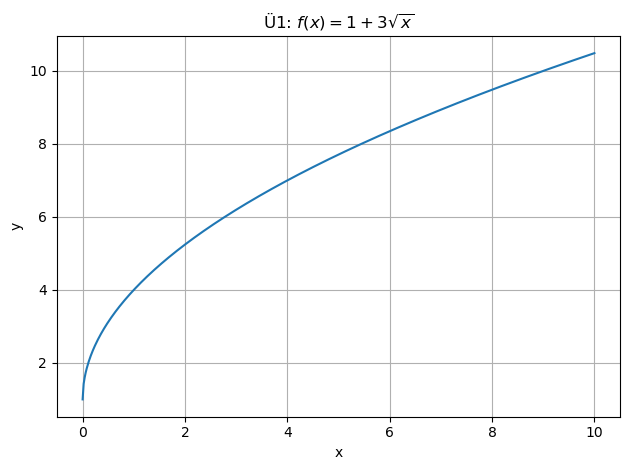

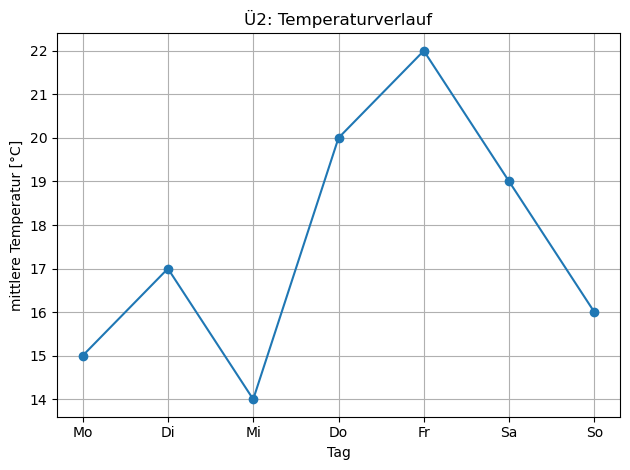

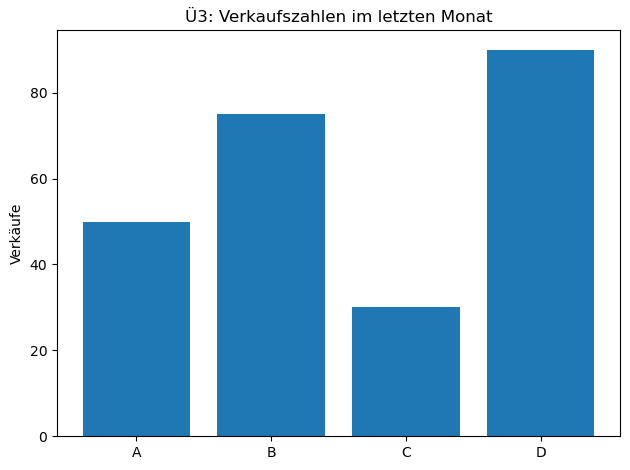

In [1]:
#| code-fold: true
#| output: false
import matplotlib.pyplot as plt
import numpy as np

# Übung 1
xs = np.linspace(0, 10, 500)
ys = 1 + 3 * np.sqrt(xs)

plt.plot(xs, ys)

plt.title(r"Ü1: $f(x)= 1 + 3\sqrt{x}$")  # das kleine r: raw string, damit der Backslash \ als solcher erkannt wird
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.grid(True)

plt.show()

# Übung 2

days = ['Mo', 'Di', 'Mi', 'Do', 'Fr', 'Sa', 'So']
temperatures = np.array([15, 17, 14, 20, 22, 19, 16])

plt.plot(days, temperatures, marker='o') # mit marker='o' markieren wir die Einzelpunkte
# scatter-Plot wäre auch möglich


plt.title("Ü2: Temperaturverlauf")
plt.xlabel("Tag")
plt.ylabel("mittlere Temperatur [°C]")
plt.tight_layout()
plt.grid(True)

plt.show()

# Übung 3

products = ["A", "B", "C", "D"]
sales_numbers = [50, 75, 30, 90]

plt.bar(products, sales_numbers)

plt.title("Ü3: Verkaufszahlen im letzten Monat")
plt.ylabel("Verkäufe")
plt.tight_layout()

plt.show()


## pandas

**pandas** ist eine Python-Bibliothek zur Datenanalyse und -verarbeitung. Sie macht es einfach, mit tabellarischen Daten zu arbeiten – wie man es von Excel oder MATLAB kennt, nur viel mächtiger! Sie ist ideal für CSV-Dateien, Zeitreihen, Sensorlogs usw. (Wie man Text- und CSV-Dateien auch ohne pandas liest und schreibt, zeigt [Anhang A](A-dateien.ipynb).)

Stellen Sie sich vor, Sie hätten eine CSV-Datei `pruefstand.csv`, die Messdaten von einem Elektromotor-Prüfstand auflistet, evtl. mit Tausenden oder Zehntausenden an Einträgen (die folgenden Beispieldaten sind simuliert, orientieren sich aber an einem typischen 5,5-kW-Asynchronmotor):

    zeit_s,drehzahl_rpm,drehmoment_Nm,temperatur_C,strom_A,spannung_V
    0,1467.2924821489682,33.81031628726315,24.628518648371458,10.215086869820023,400.3974511569548
    2,1461.4533926626523,35.36085692530741,25.32622786824618,10.628453711233902,400.8363769172621
    4,1459.7331276504278,32.1555104756014,25.657537051768216,9.701252783384483,400.41566280600614
    6,1453.9484770091583,37.09365756516304,25.88773307868301,11.153416913010403,400.690401682028
    8,1455.7907345141277,35.957442111392325,25.807826294286944,10.844172930105008,398.82854176534335
    10,1461.721999729195,34.56192877217096,25.848570214283473,10.556782004465514,400.4478068464831
    ...

Mit pandas ist es ein Leichtes, die Daten zu analysieren! Wir zeigen nur ein paar wenige der vielen Features, die pandas anbietet.

In [3]:
import pandas as pd

# CSV einlesen (statt eines Dateipfads ist auch eine URL möglich)
df = pd.read_csv(r"./data/pruefstand.csv")

# Excel-Dateien liest man analog mit pd.read_excel("datei.xlsx") ein
# (benötigt das Paket openpyxl, in Anaconda bereits enthalten)

# Die Abkürzung df ist sehr gebräuchlich und steht für 'Data Frame' = eine Tabelle

# Kurze Übersicht der Daten
df.head()  # Zeigt die ersten 5 Zeilen

,zeit_s,drehzahl_rpm,drehmoment_Nm,temperatur_C,strom_A,spannung_V
0,0,1467.292482,33.810316,24.628519,10.215087,400.397451
1,2,1461.453393,35.360857,25.326228,10.628454,400.836377
2,4,1459.733128,32.155510,25.657537,9.701253,400.415663
3,6,1453.948477,37.093658,25.887733,11.153417,400.690402
4,8,1455.790735,35.957442,25.807826,10.844173,398.828542


In [4]:
df.describe()  # liefert statistische Kennzahlen aller Größen

,zeit_s,drehzahl_rpm,drehmoment_Nm,temperatur_C,strom_A,spannung_V
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,499.000000,1459.727502,35.047270,51.742815,10.586593,399.899417
std,288.963666,3.537586,1.571831,10.276739,0.479168,0.963109
min,0.000000,1448.249747,29.378879,24.628519,8.965309,396.941205
25%,249.500000,1457.498059,33.962797,45.445497,10.220183,399.231993
50%,499.000000,1459.804317,35.094876,55.402018,10.580069,399.918036
75%,748.500000,1462.151006,36.080189,60.201944,10.890667,400.562544
max,998.000000,1471.917075,39.726362,63.147595,12.028734,403.333527


Der `describe`-Befehl ist sehr nützlich: Wir sehen auf einen Blick, dass unsere Datei 500 Zeilen beinhaltet und erhalten Mittelwerte, Standardabweichungen, Wertebereiche und Quantile aller Messgrößen. Ein erster aufschlussreicher Überblick über unsere Daten!  

In [5]:
# Mittelwerte oder andere Kennzahlen können 
# ganz einfach auch einzeln abgefragt werden:

mean_torque = df["drehmoment_Nm"].mean()
print(f"Mittleres Drehmoment: {round(mean_torque, 2)} Nm")

mean_temperature = df["temperatur_C"].mean()
print(f"Mittlere Temperatur: {round(mean_temperature, 2)} °C")

# Wie diese Beispiele zeigen, greift man auf einzelne Spalten
# eines Data Frames über einen Indexzugriff zu, ganz analog zu
# Dictionaries.


Mittleres Drehmoment: 35.05 Nm
Mittlere Temperatur: 51.74 °C


Sie können auch einfach neue Spalten erzeugen, wie das folgende Beispiel zeigt. Wir berechnen aus dem Drehmoment $M$ (in Nm) und der Drehzahl $n$ (in Umdrehungen pro Minute) die mechanische Leistung $P = M \cdot 2\pi n / 60$ in Watt:

In [6]:
# neue Spalte: mechanische Leistung P = M · ω mit ω = 2π · n / 60
df["p_mech_W"] = df["drehmoment_Nm"] * 2 * np.pi * df["drehzahl_rpm"] / 60
df.head()  # achten Sie auf die neue Spalte.

,zeit_s,drehzahl_rpm,drehmoment_Nm,temperatur_C,strom_A,spannung_V,p_mech_W
0,0,1467.292482,33.810316,24.628519,10.215087,400.397451,5195.107562
1,2,1461.453393,35.360857,25.326228,10.628454,400.836377,5411.733090
2,4,1459.733128,32.155510,25.657537,9.701253,400.415663,4915.384443
3,6,1453.948477,37.093658,25.887733,11.153417,400.690402,5647.773785
4,8,1455.790735,35.957442,25.807826,10.844173,398.828542,5481.713820


Selbstverständlich können wir nun auch Matplotlib in Kombination mit pandas einsetzen, um Daten zu visualisieren: 

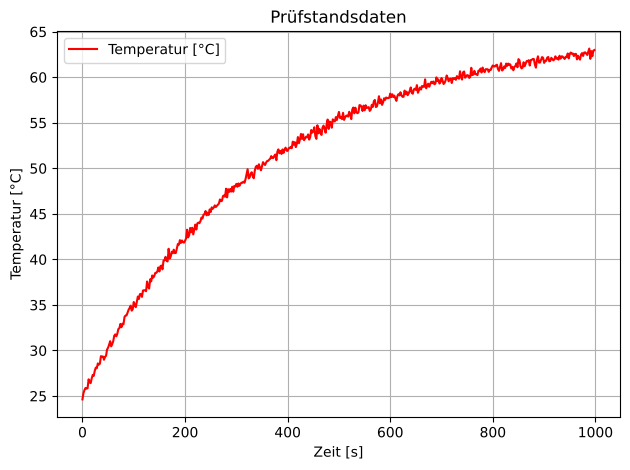

In [7]:
import matplotlib.pyplot as plt

# Plot: Temperatur über Zeit
plt.plot(df["zeit_s"], df["temperatur_C"], label="Temperatur [°C]", color="red")

plt.xlabel("Zeit [s]")
plt.ylabel("Temperatur [°C]")
plt.title("Prüfstandsdaten")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

<div class="exercises">
<b>Übung:</b>
Der Motor am Prüfstand ist ein Drehstrommotor. Seine aufgenommene elektrische Wirkleistung berechnet sich aus der Leiterspannung $U$, dem Strom $I$ und dem Leistungsfaktor $\cos\varphi$ (laut Typenschild 0,83) zu $P_{el} = \sqrt{3} \cdot U \cdot I \cdot \cos\varphi$.

1. Fügen Sie dem Data Frame eine Spalte `p_el_W` mit der elektrischen Leistung hinzu.
2. Berechnen Sie für jeden Zeitpunkt den Wirkungsgrad $\eta = P_{mech} / P_{el}$ als neue Spalte und geben Sie den mittleren Wirkungsgrad aus.
3. Ist das Ergebnis plausibel? (Typische Wirkungsgrade von Asynchronmotoren dieser Größe liegen bei 85 bis 90 %.)
</div>

Lösung:

In [ ]:
#| code-fold: true
#| output: false
# 1. Elektrische Wirkleistung (Drehstrom)
cos_phi = 0.83
df["p_el_W"] = np.sqrt(3) * df["spannung_V"] * df["strom_A"] * cos_phi

# 2. Wirkungsgrad je Zeitpunkt und Mittelwert
df["wirkungsgrad"] = df["p_mech_W"] / df["p_el_W"]
print(f"Mittlerer Wirkungsgrad: {df['wirkungsgrad'].mean():.1%}")

# 3. Mit rund 88 % liegt der Wirkungsgrad im typischen Bereich – die Messdaten sind plausibel.

Mittlerer Wirkungsgrad: 88.0%


Ein Data Frame kann auch aus einem Dictionary erzeugt werden: 

In [212]:
import pandas as pd

data = {
    'Produkt': ['Produkt A', 'Produkt B', 'Produkt C', 'Produkt D'],
    'Preis': [20, 35, 50, 15],
    'Verkaufte Menge': [100, 150, 80, 200]
}

df = pd.DataFrame(data)
df.head()

,Produkt,Preis,Verkaufte Menge
0,Produkt A,20,100
1,Produkt B,35,150
2,Produkt C,50,80
3,Produkt D,15,200


<div class="exercises">
<b>Übungen:</b>
Erzeugen Sie das Data Frame, wie im letzten Beispiel gezeigt. 

1. Fügen Sie eine Spalte Umsatz hinzu (Umsatz = Preis * Verkaufte Menge). 
2. Finden Sie das Produkt mit dem höchsten Umsatz. 
3. Erstellen Sie ein Balkendiagramm mit Matplotlib, das den Umsatz jedes Produkts zeigt.
4. Wie groß sind Mittelwert und Standardabweichung des Umsatzes?
</div>

Lösung:

     Produkt  Preis  Verkaufte Menge  Umsatz
0  Produkt A     20              100    2000
1  Produkt B     35              150    5250
2  Produkt C     50               80    4000
3  Produkt D     15              200    3000


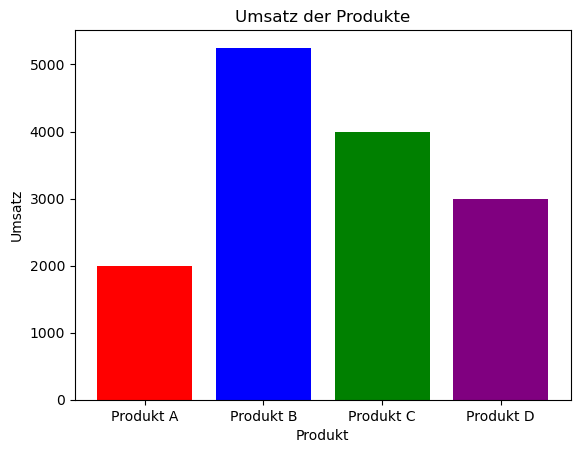

Mittlerer Umsatz:  3562.5 Standardabweichung:  1390.0689431343565


,Preis,Verkaufte Menge,Umsatz
count,4.000000,4.000000,4.000000
mean,30.000000,132.500000,3562.500000
std,15.811388,53.774219,1390.068943
min,15.000000,80.000000,2000.000000
25%,18.750000,95.000000,2750.000000
50%,27.500000,125.000000,3500.000000
75%,38.750000,162.500000,4312.500000
max,50.000000,200.000000,5250.000000


In [216]:
#| code-fold: true
#| output: false
import pandas as pd
import matplotlib.pyplot as plt

# Daten erstellen
data = {
    'Produkt': ['Produkt A', 'Produkt B', 'Produkt C', 'Produkt D'],
    'Preis': [20, 35, 50, 15],
    'Verkaufte Menge': [100, 150, 80, 200]
}

df = pd.DataFrame(data)

# 1. Umsatz berechnen und als Spalte hinzufügen
df['Umsatz'] = df['Preis'] * df['Verkaufte Menge']

# 2. Kann durch einfaches print gelöst werden:
print(df)  # Produkt B hat den höchsten Umsatz!

# 3. Balkendiagramm erstellen
plt.bar(df['Produkt'], df['Umsatz'], color=['red', 'blue', 'green', 'purple'])
plt.title('Umsatz der Produkte')
plt.xlabel('Produkt')
plt.ylabel('Umsatz')

plt.show()

# 4. Statistische Kennzahlen
print("Mittlerer Umsatz: ", df['Umsatz'].mean(), "Standardabweichung: ", df['Umsatz'].std())
# Hinweis: pandas teilt bei .std() durch n-1 (Stichproben-Standardabweichung), np.std() dagegen
# standardmäßig durch n. Bei großen Datenmengen spielt das kaum eine Rolle, bei nur 4 Werten wie
# hier ist der Unterschied aber deutlich (np.std() ergäbe ca. 1204 statt 1390).
# Kann auch über describe abgelesen werden: 
df.describe()